# Baseline Analysis

Everything about the seven baselines in one place, model by model.

1. **Train** — every model on each of the 5 folds, and once on the full 245 days
2. **Forecasts** — a 3 × 3 grid per model: 3 turbines × 3 windows
3. **Fold scores** — per-fold, mean and spread, for every model
4. **Competition score** — the official grader on `final_phase_test`


| trained on | used for | why |
|---|---|---|
| each fold's `fold_train.csv` | the 5-fold CV scores | each fold must only see data before its own validation period |
| the full 245-day file | the `final_phase_test` score | the test windows come *after* day 245, so all 245 days are legitimately available |

Using a fold model on the test set would waste data; using the full model on a
fold would leak that fold's validation period into training. Both are built.

### Cost

**This notebook trains 42 models** (7 models × 6, minus climatology which fits
nothing — so 36 files). Set `TRAIN = False` to reuse whatever already exists.

They are saved in each baseline's own folder, e.g.
`baselines/gru/checkpoints/gru_F3.pt`, which is where that model already looks by
default.

In [1]:
import os, sys, glob, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
if os.path.basename(_ROOT) != "windevolve_sdwpf":
    _ROOT = os.path.join(_ROOT, "windevolve_sdwpf")
for sub in ["", "evaluation", "analysis"]:
    p = os.path.join(_ROOT, sub)
    if p not in sys.path:
        sys.path.insert(0, p)

# A WRONG SDWPF_DATA_DIR overrides paths.py's fallback, and Jupyter inherits the
# environment from whenever the kernel started. Resolve before importing anything.
def _paths_ok():
    import importlib, paths
    importlib.reload(paths)
    return os.path.exists(paths.TRAIN_FILE) and os.path.exists(paths.LOCATION_FILE)

if not _paths_ok() and os.environ.get("SDWPF_DATA_DIR"):
    print("dropping bad SDWPF_DATA_DIR={!r}".format(os.environ.pop("SDWPF_DATA_DIR")))
if not _paths_ok():
    hits = glob.glob(os.path.join(os.path.expanduser("~"), "**",
                                  "sdwpf_245days_v1.csv"), recursive=True)
    if hits:
        os.environ["SDWPF_DATA_DIR"] = os.path.dirname(hits[0])

import paths as P
if not _paths_ok():
    raise SystemExit(
        "data paths do not resolve. Restart the kernel from a shell where\n"
        "`env | grep SDWPF` is clean, or set SDWPF_DATA_DIR to the directory\n"
        "holding sdwpf_245days_v1.csv AND the turbine location CSV.")

FOLDS_ROOT = os.environ.get("SDWPF_FOLDS_ROOT",
                            os.path.join(_ROOT, "evaluation", "splits_rolling_5x30"))
BASELINES = os.path.join(_ROOT, "baselines")

TRAIN = True          # False = reuse whatever artifacts already exist
RUN_TEST = True       # False = skip the final_phase_test section entirely

# Trained models live in each model's OWN folder, e.g.
#     baselines/gru/checkpoints/gru_F3.pt
# which is where that baseline looks by default. Nothing is written to runs/ --
# every figure and table stays in this notebook.

# One colour per model, from matplotlib's default tab10 cycle. Truth is black so
# it reads as the reference line against any model colour.
_CYCLE = plt.rcParams["axes.prop_cycle"].by_key()["color"]
COLOURS = {name: _CYCLE[i % len(_CYCLE)] for i, name in enumerate(
    ["gru", "gbdt", "arma", "lstm", "mlp", "transformer", "climatology"])}
COLOURS["actual"] = "black"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False})
print("train file :", P.TRAIN_FILE)
print("locations  :", P.LOCATION_FILE)
print("test dir   :", P.TEST_DIR, "|", "found" if os.path.isdir(P.TEST_DIR) else "MISSING")
print("folds      :", FOLDS_ROOT)
print("baselines  :", BASELINES)

train file : /home/dorsa2026/windevolve/wind_forecasting_data/sdwpf_kddcup/sdwpf_245days_v1.csv
locations  : /home/dorsa2026/windevolve/wind_forecasting_data/sdwpf_kddcup/sdwpf_baidukddcup2022_turb_location.csv
test dir   : /home/dorsa2026/windevolve/wind_forecasting_data/sdwpf_kddcup/final_phase_test | found
folds      : /home/dorsa2026/windevolve/windevolve_sdwpf/evaluation/splits_rolling_5x30
baselines  : /home/dorsa2026/windevolve/windevolve_sdwpf/baselines


## 1 · The seven baselines

Each entry says where the file is, which environment variable points it at an
artifact, and how to train one. The `{fold}` placeholder is filled at scoring
time from `envs["fold"]`; the full-data artifact has no placeholder.

In [2]:
import evaluator as EV
import official_metrics as OM
from test_data import TestData
EV.LOCATION_FILE = P.LOCATION_FILE

FOLDS = [os.path.basename(d) for d in sorted(glob.glob(os.path.join(FOLDS_ROOT, "F*")))]
FOLD_TRAIN = {f: os.path.join(FOLDS_ROOT, f, "fold_train.csv") for f in FOLDS}
print("folds:", FOLDS)


def _neural(train_csv, out_path, mod):
    mod.train(train_csv=train_csv, ckpt_path=out_path, verbose=False)

def _gbdt(train_csv, out_path, mod):
    mod.train(csv_path=train_csv, model_path=out_path)

def _arma(train_csv, out_path, mod):
    # fit_steps is trailing, so cap it at what this prefix actually holds --
    # F1 has only 95 days and the default asks for 30.
    rows = sum(1 for _ in open(train_csv)) - 1
    per_turbine = rows // mod.CAPACITY
    mod.fit_all(csv_path=train_csv, turbines=None, order=mod.DEFAULT_ORDER,
                fit_steps=min(mod.FIT_STEPS, per_turbine), model_path=out_path)

MODELS = {
    "gru":         dict(path="gru/gru_baseline.py",   env="SDWPF_GRU_CKPT",
                        ext="pt",     trainer=_neural, champion="hidden = 96"),
    "gbdt":        dict(path="tree/baseline_gbdt.py", env="SDWPF_GBDT_MODEL",
                        ext="joblib", trainer=_gbdt,   champion="tier = base+nbr"),
    "arma":        dict(path="classical/baseline_arima.py", env="SDWPF_ARIMA_MODEL",
                        ext="joblib", trainer=_arma,   champion="order = (2,0,1)"),
    "lstm":        dict(path="lstm/lstm.py",          env="SDWPF_LSTM_CKPT",
                        ext="pt",     trainer=_neural, champion="GRU-matched"),
    "mlp":         dict(path="mlp/mlp.py",            env="SDWPF_MLP_CKPT",
                        ext="pt",     trainer=_neural, champion="scope = global"),
    "transformer": dict(path="transformer/transformer.py", env="SDWPF_TST_CKPT",
                        ext="pt",     trainer=_neural, champion="patch_len = 24"),
    "climatology": dict(path="classical/baseline_climatology.py", env=None,
                        ext=None,     trainer=None,    champion="n_days = 14"),
}

def art_path(name, tag):
    """
    Where one artifact lives: inside that model's own folder, under checkpoints/.
    tag is a fold name ('F3') or 'full'.

        baselines/gru/checkpoints/gru_F3.pt
        baselines/tree/checkpoints/gbdt_full.joblib

    That is the directory each baseline already looks in by default, so a model
    trained here is usable straight from the command line.
    """
    spec = MODELS[name]
    if spec["ext"] is None:
        return None
    folder = os.path.join(BASELINES, os.path.dirname(spec["path"]), "checkpoints")
    os.makedirs(folder, exist_ok=True)
    return os.path.join(folder, "{}_{}.{}".format(name, tag, spec["ext"]))

def load_model(name, tag):
    """
    Load a baseline pointed at ONE artifact. The env var is set before import so
    the module picks it up as its module-level constant.
    """
    spec = MODELS[name]
    if spec["env"]:
        os.environ[spec["env"]] = art_path(name, tag)
    import importlib.util
    full = os.path.join(_ROOT, "baselines", spec["path"])
    s = importlib.util.spec_from_file_location("bl_{}_{}".format(name, tag), full)
    mod = importlib.util.module_from_spec(s)
    s.loader.exec_module(mod)
    # Invalidate any cached artifact WITHOUT removing keys: baseline_gbdt indexes
    # _CACHE["model"] directly, so .clear() would raise a KeyError on first use.
    if hasattr(mod, "_CACHE") and isinstance(mod._CACHE, dict):
        for k in list(mod._CACHE):
            mod._CACHE[k] = None
    return mod

print("\n%-13s %-22s %s" % ("model", "champion", "file"))
print("-" * 76)
for n, s in MODELS.items():
    print("%-13s %-22s %s" % (n, s["champion"], s["path"]))

folds: ['F1', 'F2', 'F3', 'F4', 'F5']

model         champion               file
----------------------------------------------------------------------------
gru           hidden = 96            gru/gru_baseline.py
gbdt          tier = base+nbr        tree/baseline_gbdt.py
arma          order = (2,0,1)        classical/baseline_arima.py
lstm          GRU-matched            lstm/lstm.py
mlp           scope = global         mlp/mlp.py
transformer   patch_len = 24         transformer/transformer.py
climatology   n_days = 14            classical/baseline_climatology.py


## 2 · Train

**Six artifacts per model:** one per fold, plus one on the full 245 days.
Existing artifacts are skipped, so this is safe to re-run.

Watch the printed times on the first model before walking away — ARMA fits 134
models per artifact and is by far the slowest.

In [3]:
jobs = []
for name, spec in MODELS.items():
    if spec["trainer"] is None:
        continue
    for tag, csv in list(zip(FOLDS, [FOLD_TRAIN[f] for f in FOLDS])) + [("full", P.TRAIN_FILE)]:
        out = art_path(name, tag)
        if not os.path.exists(out):
            jobs.append((name, tag, csv, out))

have = sum(1 for n, s in MODELS.items() if s["trainer"] is not None
           for t in FOLDS + ["full"] if os.path.exists(art_path(n, t)))
print("artifacts present: {} / 36   (climatology needs none)".format(have))
print("to build         : {}".format(len(jobs)))

if not TRAIN and jobs:
    print("\nTRAIN is False -- {} artifacts will be missing and those models will".format(len(jobs)))
    print("be skipped below. Set TRAIN = True to build them.")
elif jobs:
    print("\nbuilding ...\n")
    t_all = time.perf_counter()
    for i, (name, tag, csv, out) in enumerate(jobs, 1):
        t0 = time.perf_counter()
        mod = load_model(name, tag)
        try:
            MODELS[name]["trainer"](csv, out, mod)
            print("[{:>2}/{}] {:<13} {:<5} {:>7.1f}s".format(
                i, len(jobs), name, tag, time.perf_counter() - t0))
        except Exception as e:
            print("[{:>2}/{}] {:<13} {:<5} FAILED: {}: {}".format(
                i, len(jobs), name, tag, type(e).__name__, str(e)[:70]))
    print("\ntotal {:.1f} min".format((time.perf_counter() - t_all) / 60))
else:
    print("\nnothing to build")

artifacts present: 0 / 36   (climatology needs none)
to build         : 36

building ...

[ 1/36] gru           F1       55.4s
[ 2/36] gru           F2       72.3s
[ 3/36] gru           F3       90.5s
[ 4/36] gru           F4      108.7s
[ 5/36] gru           F5      140.5s
[ 6/36] gru           full    145.4s
building training set from /home/dorsa2026/windevolve/windevolve_sdwpf/evaluation/splits_rolling_5x30/F1/fold_train.csv
  feature set: base+nbr (15 features)
  482,400 rows x 15 features in 1.6s
  fitted 200 trees in 0.5s
saved to /home/dorsa2026/windevolve/windevolve_sdwpf/baselines/tree/checkpoints/gbdt_F1.joblib
[ 7/36] gbdt          F1        2.6s
building training set from /home/dorsa2026/windevolve/windevolve_sdwpf/evaluation/splits_rolling_5x30/F2/fold_train.csv
  feature set: base+nbr (15 features)
  482,400 rows x 15 features in 1.9s
  fitted 200 trees in 0.5s
saved to /home/dorsa2026/windevolve/windevolve_sdwpf/baselines/tree/checkpoints/gbdt_F2.joblib
[ 8/36] gbdt     

In [4]:
# Which models are fully usable, and for what.
status = []
for name, spec in MODELS.items():
    if spec["trainer"] is None:
        status.append(dict(model=name, folds_ready=len(FOLDS), full_ready=True))
        continue
    ready = [f for f in FOLDS if os.path.exists(art_path(name, f))]
    status.append(dict(model=name, folds_ready=len(ready),
                       full_ready=os.path.exists(art_path(name, "full"))))
status = pd.DataFrame(status)
status["cv_ok"] = status["folds_ready"] == len(FOLDS)
display(status)

CV_MODELS = list(status[status["cv_ok"]]["model"])
TEST_MODELS = list(status[status["full_ready"]]["model"])
print("scoreable on folds :", ", ".join(CV_MODELS))
print("scoreable on test  :", ", ".join(TEST_MODELS))

,model,folds_ready,full_ready,cv_ok
0,gru,5,True,True
1,gbdt,5,True,True
2,arma,5,True,True
3,lstm,5,True,True
4,mlp,5,True,True
5,transformer,5,True,True
6,climatology,5,True,True


scoreable on folds : gru, gbdt, arma, lstm, mlp, transformer, climatology
scoreable on test  : gru, gbdt, arma, lstm, mlp, transformer, climatology


## 3 · Forecasts — a 3 × 3 grid per model

Three turbines down, three forecast origins across, all from the same fold.

Grey shading marks steps the official grader **excludes**, so a model looking
wrong there is not being penalised for it. The red dotted line is rated capacity
(1,500 kW) — nothing should ever cross it.

In [5]:
PLOT_FOLD = FOLDS[-1]                    # F5: the most training data
_ins, _outs = EV._list_windows(os.path.join(FOLDS_ROOT, PLOT_FOLD, "windows"))
N_W = len(_ins)
PLOT_WINDOWS = sorted(set([0, N_W // 2, N_W - 1]))[:3]   # first, middle, last
PLOT_TURBINES = [0, 66, 122]
RATED_KW = 1500.0
hours = np.arange(EV.OUTPUT_LEN) / 6.0

def official_mask(raw):
    """The grader's validity rules, from official_metrics.turbine_scores."""
    nan_cond = pd.isna(raw).any(axis=1)
    invalid = ((raw["Patv"] < 0)
               | ((raw["Patv"] == 0) & (raw["Wspd"] > 2.5))
               | ((raw["Pab1"] > 89) | (raw["Pab2"] > 89) | (raw["Pab3"] > 89))
               | ((raw["Wdir"] < -180) | (raw["Wdir"] > 180)
                  | (raw["Ndir"] < -720) | (raw["Ndir"] > 720)))
    return (~nan_cond & ~invalid).values

_truth_cache = {}
def truth_of(fold, w):
    if (fold, w) in _truth_cache:
        return _truth_cache[(fold, w)]
    ins, outs = EV._list_windows(os.path.join(FOLDS_ROOT, fold, "windows"))
    td = TestData(path_to_data=outs[w], start_col=EV.START_COL, farm_capacity=EV.CAPACITY)
    tb, raw = td.get_all_turbines()
    truth = np.zeros((EV.CAPACITY, EV.OUTPUT_LEN))
    keep = np.zeros(truth.shape, dtype=bool)
    for i in range(EV.CAPACITY):
        truth[i] = np.asarray(tb[i])[:EV.OUTPUT_LEN, -EV.OUT_VAR:].ravel()
        keep[i] = official_mask(raw[i].iloc[:EV.OUTPUT_LEN])
    _truth_cache[(fold, w)] = (truth, keep, ins[w])
    return _truth_cache[(fold, w)]

def forecast_of(name, fold, w):
    """Run one model on one window, using that fold's artifact."""
    mod = LOADED[(name, fold)]
    _, _, infile = truth_of(fold, w)
    envs = EV._prep_env(infile, FOLD_TRAIN[fold], fold)
    envs["path_to_locations"] = P.LOCATION_FILE
    return np.asarray(mod.forecast(envs)).reshape(EV.CAPACITY, EV.OUTPUT_LEN)

# load each model once per fold, reused by the plots and the scoring below
LOADED = {}
for name in CV_MODELS:
    for f in FOLDS:
        LOADED[(name, f)] = load_model(name, f)
print("loaded {} (model, fold) pairs".format(len(LOADED)))
print("plotting fold {} | windows {} | turbines {}".format(
    PLOT_FOLD, PLOT_WINDOWS, PLOT_TURBINES))

loaded 35 (model, fold) pairs
plotting fold F5 | windows [0, 7, 14] | turbines [0, 66, 122]


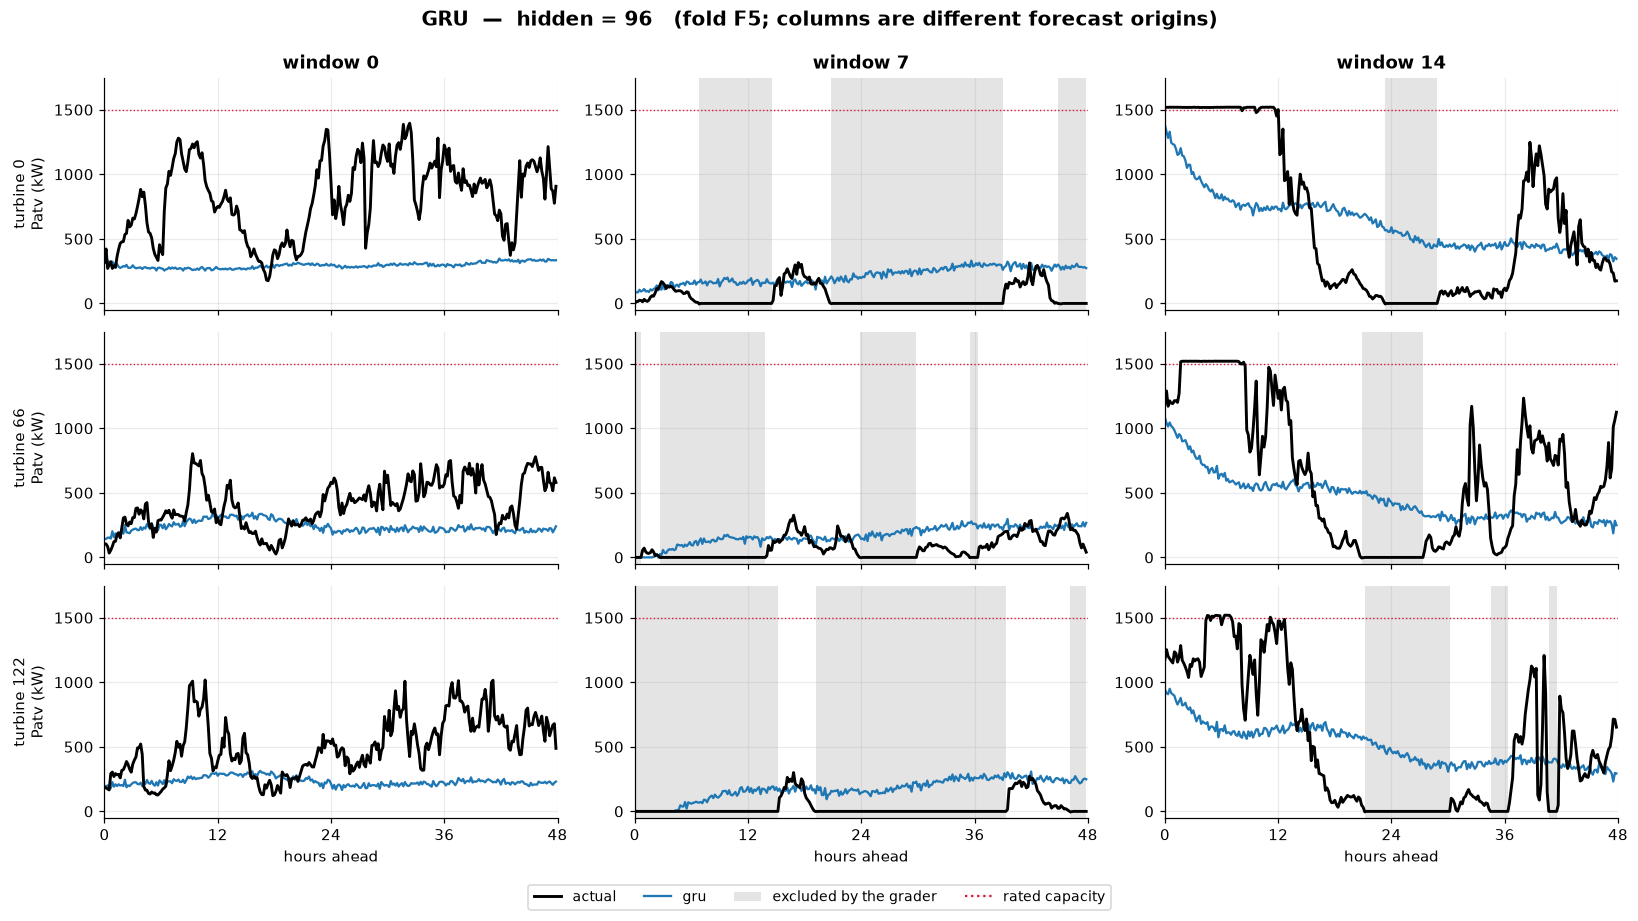

[gbdt] loading model from: /home/dorsa2026/windevolve/windevolve_sdwpf/baselines/tree/checkpoints/gbdt_F5.joblib


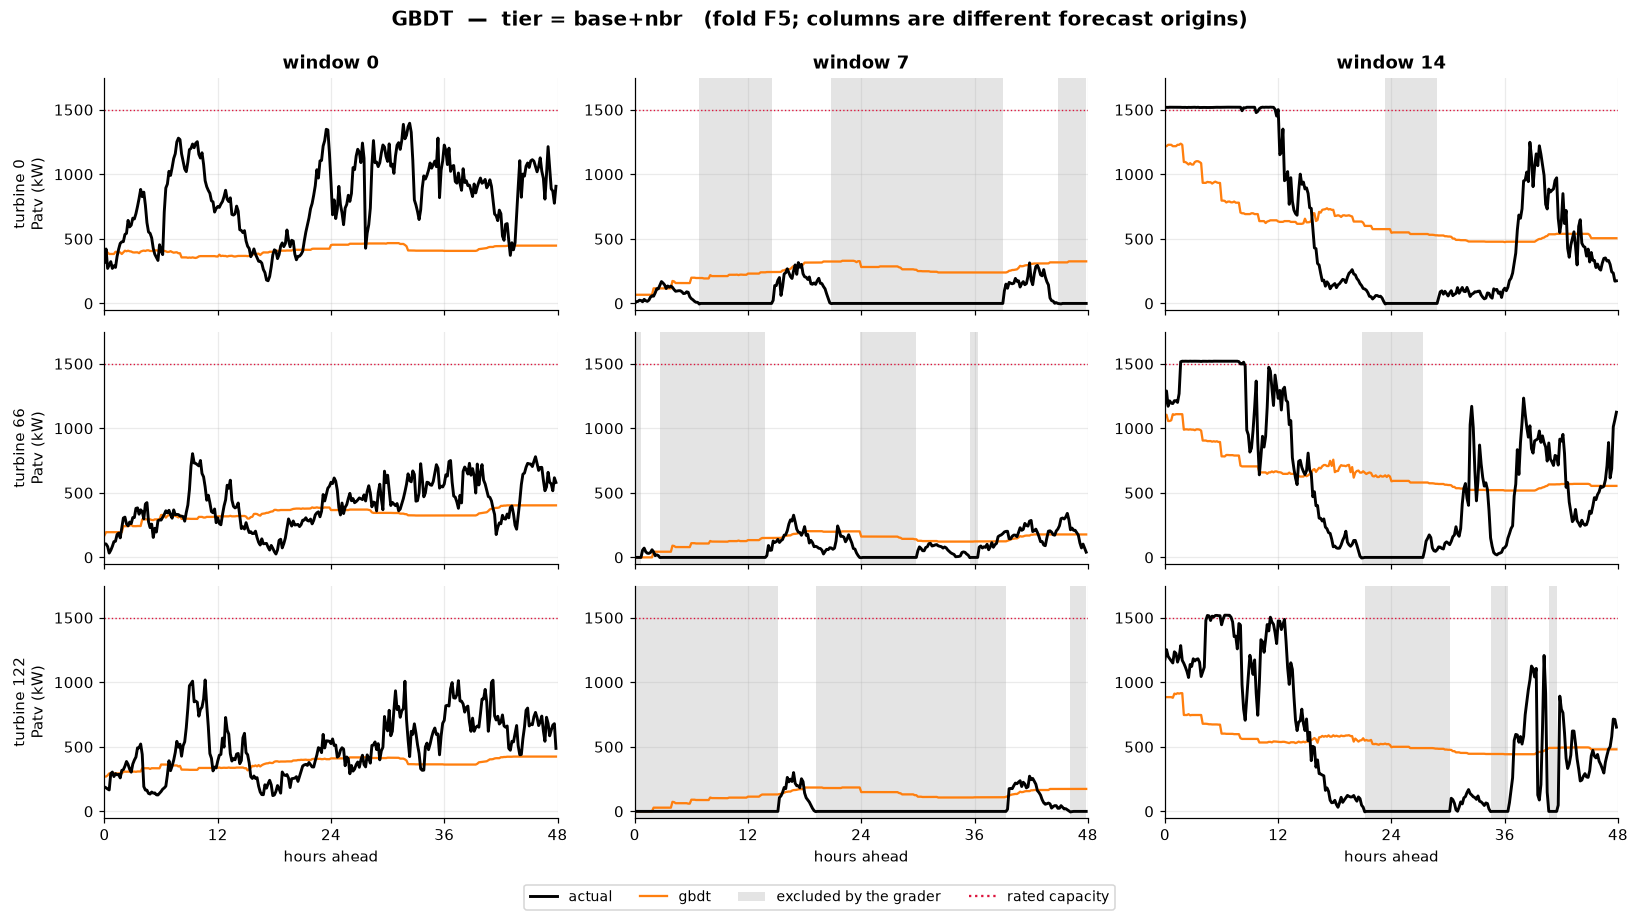

[arma] loading fits from: /home/dorsa2026/windevolve/windevolve_sdwpf/baselines/classical/checkpoints/arma_F5.joblib


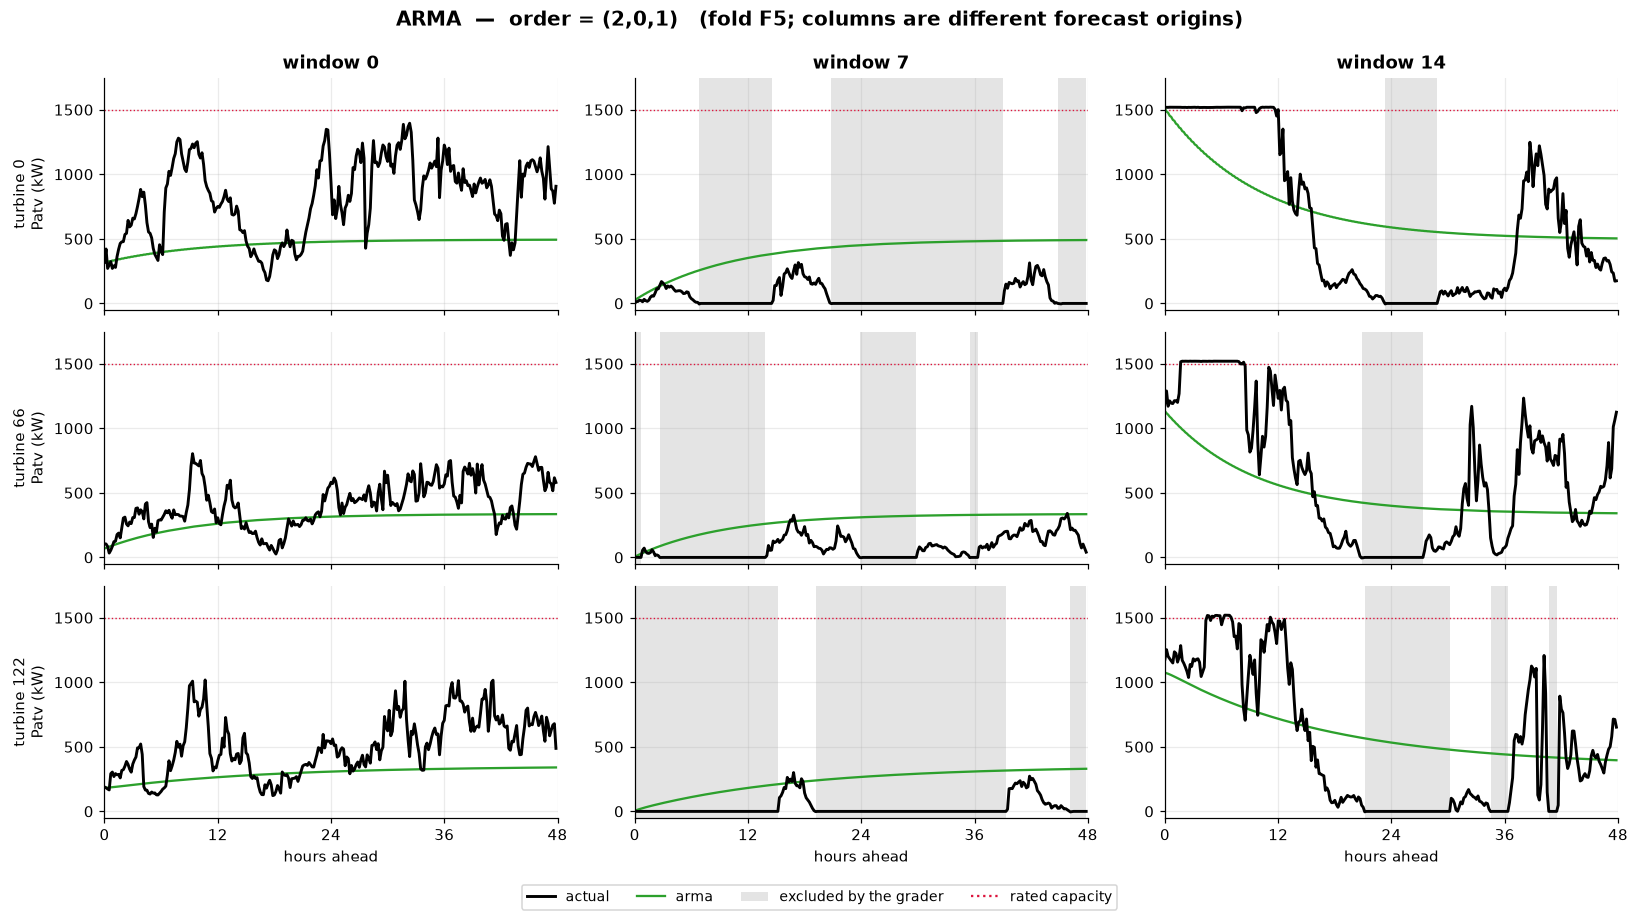

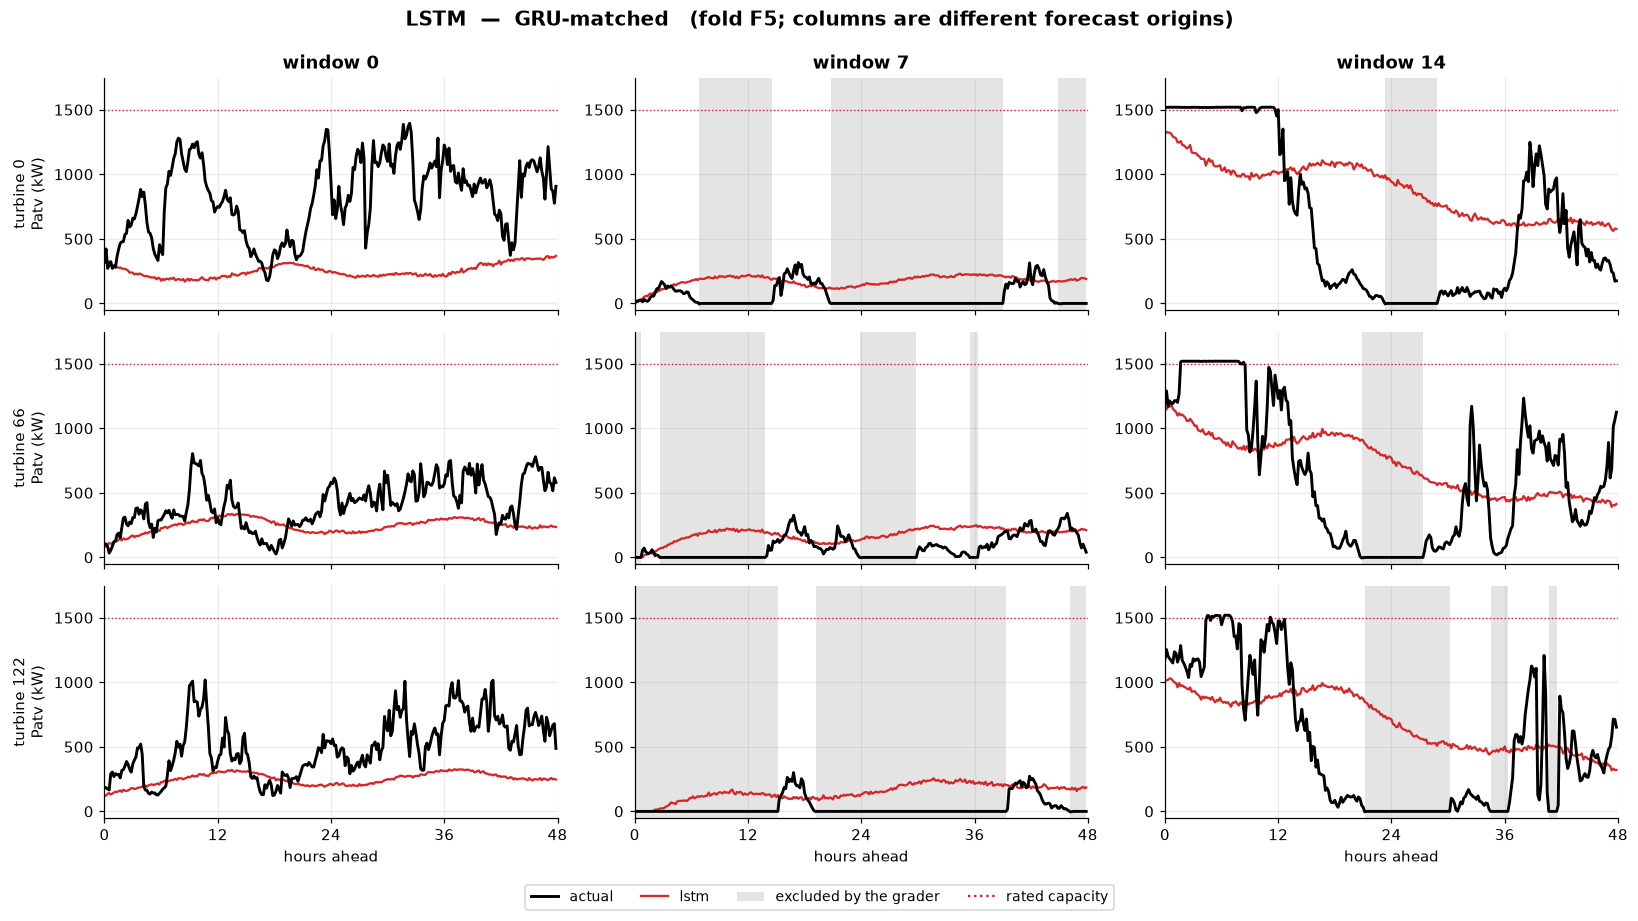

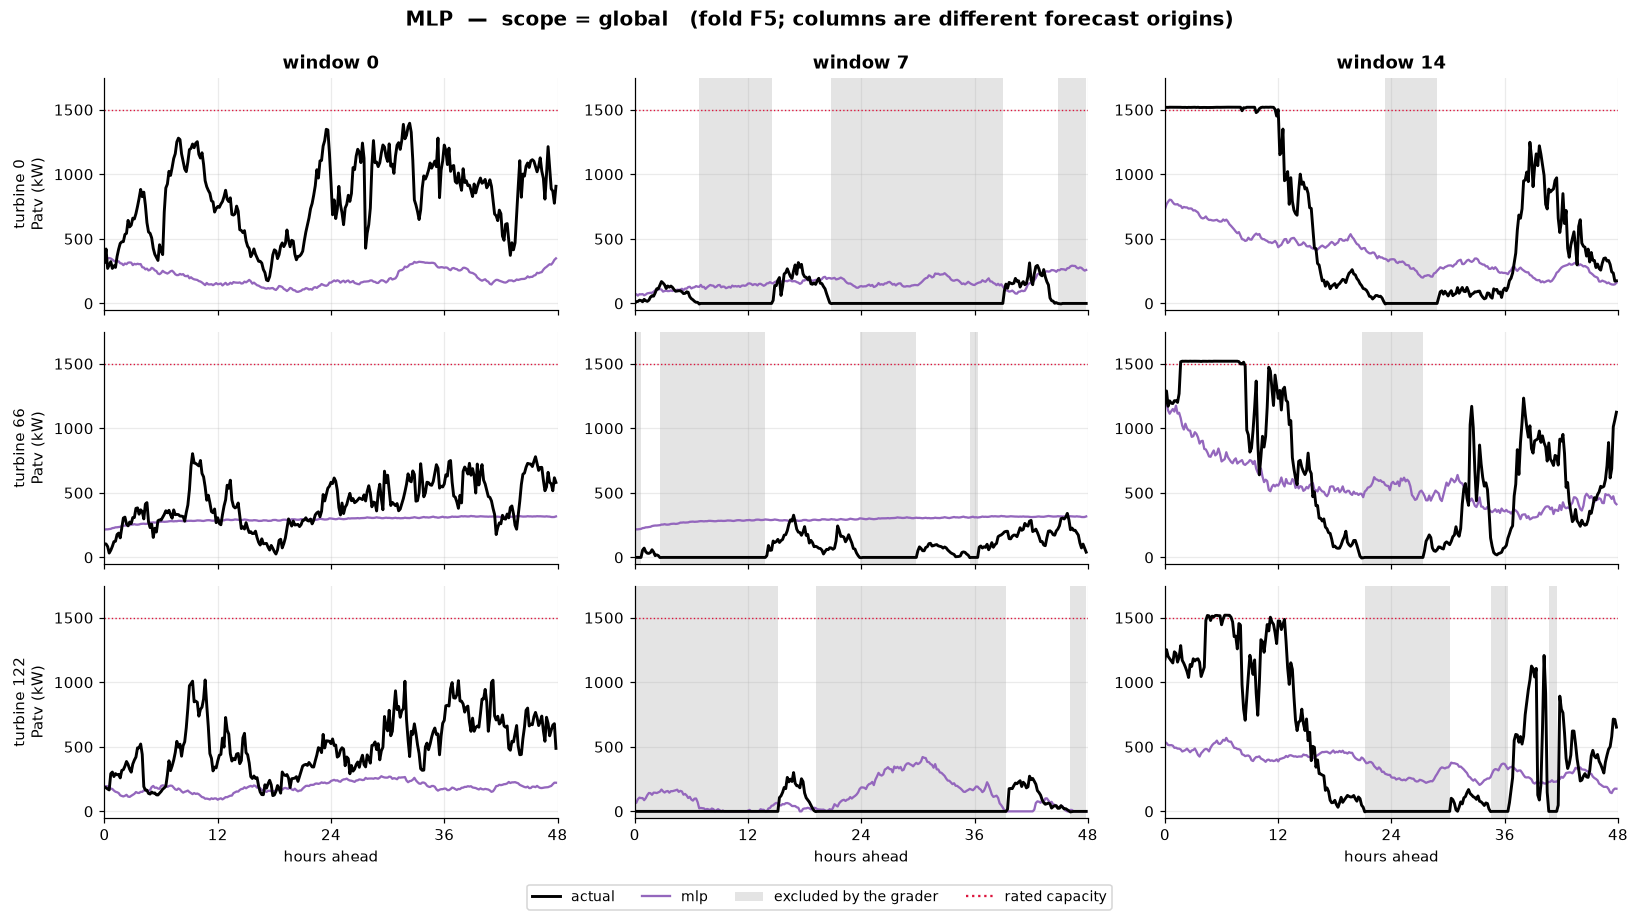

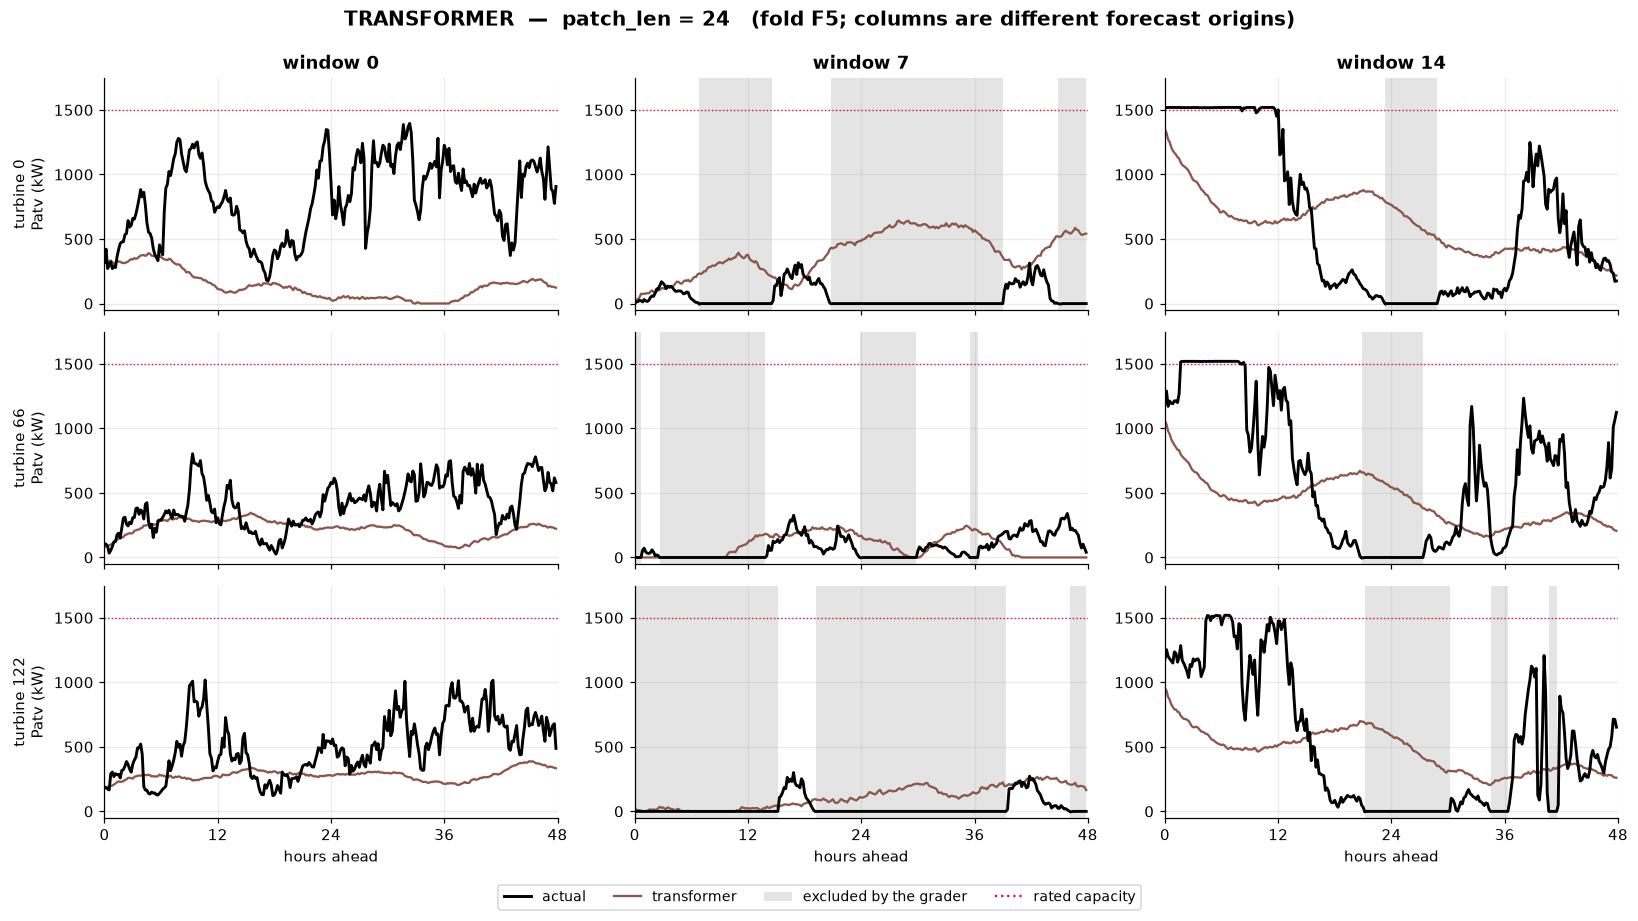

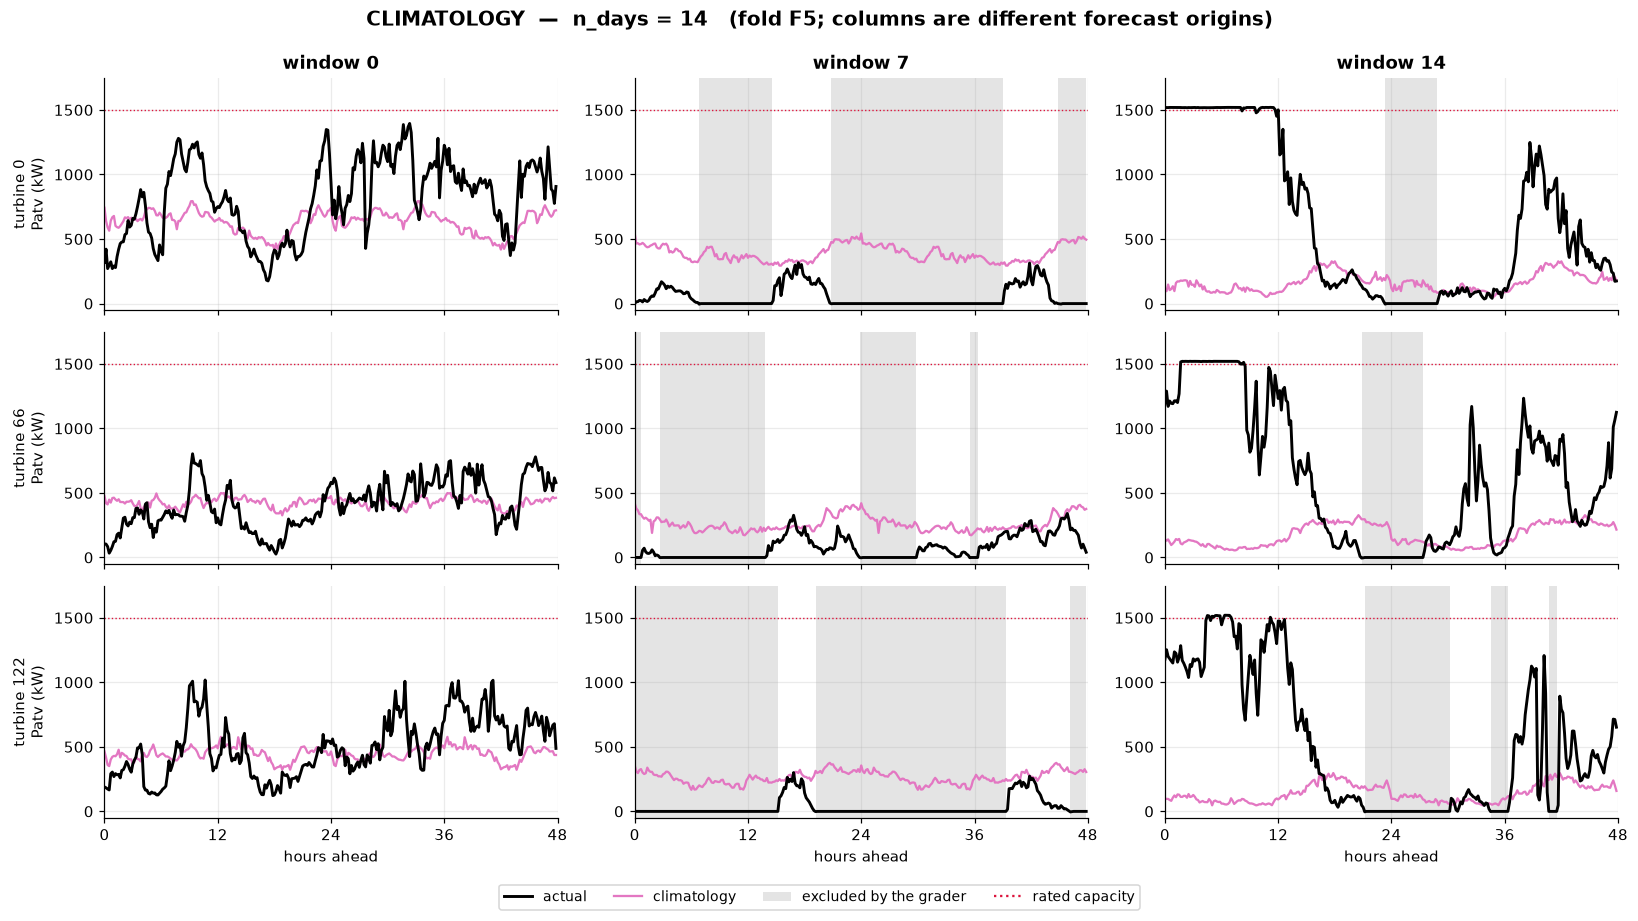

In [6]:
for name in CV_MODELS:
    preds = {w: forecast_of(name, PLOT_FOLD, w) for w in PLOT_WINDOWS}

    # one y-range for the whole grid, driven by TRUTH -- a model forecasting
    # above capacity should look wrong, not rescale the plot until it looks fine
    tmax = max(truth_of(PLOT_FOLD, w)[0][PLOT_TURBINES].max() for w in PLOT_WINDOWS)
    y_top = float(max(RATED_KW * 1.1, tmax * 1.15))

    # 3 columns when the fold has >= 3 windows; fewer otherwise, so no blank panels
    ncol = len(PLOT_WINDOWS)
    fig, axes = plt.subplots(3, ncol, figsize=(5 * ncol, 8), sharex=True, squeeze=False)
    for r, tid in enumerate(PLOT_TURBINES):
        for c, w in enumerate(PLOT_WINDOWS):
            ax = axes[r, c]
            truth, keep, _ = truth_of(PLOT_FOLD, w)
            bad = ~keep[tid]
            if bad.any():
                ax.fill_between(hours, 0, 1, where=bad,
                                transform=ax.get_xaxis_transform(),
                                color="lightgrey", alpha=0.6, linewidth=0)
            ax.axhline(RATED_KW, color="crimson", ls=":", lw=0.9)
            ax.plot(hours, truth[tid], color=COLOURS["actual"], lw=1.9,
                    label="actual", zorder=5)
            ax.plot(hours, preds[w][tid], color=COLOURS.get(name, "grey"), lw=1.5,
                    label=name)
            pk = preds[w][tid].max()
            if pk > y_top:
                ax.annotate("off scale: peaks {:.0f} kW".format(pk), (0.02, 0.95),
                            xycoords="axes fraction", fontsize=7,
                            color="crimson", va="top")
            ax.set_ylim(-50, y_top)
            ax.set_xlim(0, 48); ax.set_xticks([0, 12, 24, 36, 48])
            if r == 0:
                ax.set_title("window {}".format(w), fontweight="bold")
            if c == 0:
                ax.set_ylabel("turbine {}\nPatv (kW)".format(tid))
            if r == 2:
                ax.set_xlabel("hours ahead")

    h, l = axes[0, 0].get_legend_handles_labels()
    h.append(plt.Rectangle((0, 0), 1, 1, fc="lightgrey", alpha=0.6))
    l.append("excluded by the grader")
    h.append(plt.Line2D([0], [0], color="crimson", ls=":")); l.append("rated capacity")
    fig.legend(h, l, loc="lower center", ncol=4, fontsize=9,
               bbox_to_anchor=(0.5, -0.04))
    fig.suptitle("{}  —  {}   (fold {}; columns are different forecast origins)"
                 .format(name.upper(), MODELS[name]["champion"], PLOT_FOLD),
                 fontweight="bold", fontsize=13, y=0.99)
    plt.tight_layout()
    plt.show()

### Reading the grids

- **Flatness.** A model tracking the daily mean and ignoring the ramps is doing
  what any average-error objective asks of it at a 48-hour horizon.
- **Staircases** in the GBDT line — trees emit steps, and a visible staircase on
  a smooth quantity is RMSE paid away for nothing.
- **Decay to a constant** in ARMA — it is a geometric decay from the current
  level to the long-run mean by construction, so a flat tail is expected.
- **Anything crossing the red line** is above rated capacity and is not a
  forecast.

## 4 · Fold scores

Every model scored on all five folds with the official grader. `fold_std` is the
spread **across folds** — mostly a property of the weather in those periods, not
of the model.

In [7]:
rows = []
for name in CV_MODELS:
    per_fold, t0 = {}, time.perf_counter()
    for f in FOLDS:
        r = EV._score_forecaster(LOADED[(name, f)],
                                 os.path.join(FOLDS_ROOT, f, "windows"),
                                 train_file=FOLD_TRAIN[f], fold=f)
        per_fold[f] = r["competition_score"]
    v = np.array([per_fold[f] for f in FOLDS])
    rows.append(dict(model=name, champion=MODELS[name]["champion"],
                     **{f: round(per_fold[f], 3) for f in FOLDS},
                     cv_mean=round(float(v.mean()), 3),
                     fold_std=round(float(v.std()), 3),
                     best_fold=FOLDS[int(v.argmin())],
                     worst_fold=FOLDS[int(v.argmax())],
                     secs=round(time.perf_counter() - t0, 1)))
    print("{:<13} {:.3f} MW  +/-{:.3f}   ({:.0f}s)".format(
        name, v.mean(), v.std(), rows[-1]["secs"]))

cv = pd.DataFrame(rows).sort_values("cv_mean").reset_index(drop=True)
print()
display(cv[["model", "champion"] + FOLDS + ["cv_mean", "fold_std"]])

gru           43.591 MW  +/-5.109   (20s)
[gbdt] loading model from: /home/dorsa2026/windevolve/windevolve_sdwpf/baselines/tree/checkpoints/gbdt_F1.joblib
[gbdt] loading model from: /home/dorsa2026/windevolve/windevolve_sdwpf/baselines/tree/checkpoints/gbdt_F2.joblib
[gbdt] loading model from: /home/dorsa2026/windevolve/windevolve_sdwpf/baselines/tree/checkpoints/gbdt_F3.joblib
[gbdt] loading model from: /home/dorsa2026/windevolve/windevolve_sdwpf/baselines/tree/checkpoints/gbdt_F4.joblib
gbdt          44.079 MW  +/-5.159   (19s)
[arma] loading fits from: /home/dorsa2026/windevolve/windevolve_sdwpf/baselines/classical/checkpoints/arma_F1.joblib
[arma] loading fits from: /home/dorsa2026/windevolve/windevolve_sdwpf/baselines/classical/checkpoints/arma_F2.joblib
[arma] loading fits from: /home/dorsa2026/windevolve/windevolve_sdwpf/baselines/classical/checkpoints/arma_F3.joblib
[arma] loading fits from: /home/dorsa2026/windevolve/windevolve_sdwpf/baselines/classical/checkpoints/arma_F4.job

,model,champion,F1,F2,F3,F4,F5,cv_mean,fold_std
0,gru,hidden = 96,46.080,47.452,39.488,49.178,35.759,43.591,5.109
1,gbdt,tier = base+nbr,47.222,47.735,40.051,49.393,35.994,44.079,5.159
2,arma,"order = (2,0,1)",47.085,48.122,39.633,47.811,38.850,44.300,4.152
3,lstm,GRU-matched,45.959,48.134,42.951,51.905,36.464,45.083,5.205
4,transformer,patch_len = 24,45.326,50.488,40.868,54.480,39.691,46.171,5.630
5,mlp,scope = global,47.585,49.716,42.314,54.559,38.814,46.598,5.532
6,climatology,n_days = 14,52.992,54.556,42.294,52.462,40.152,48.491,6.012


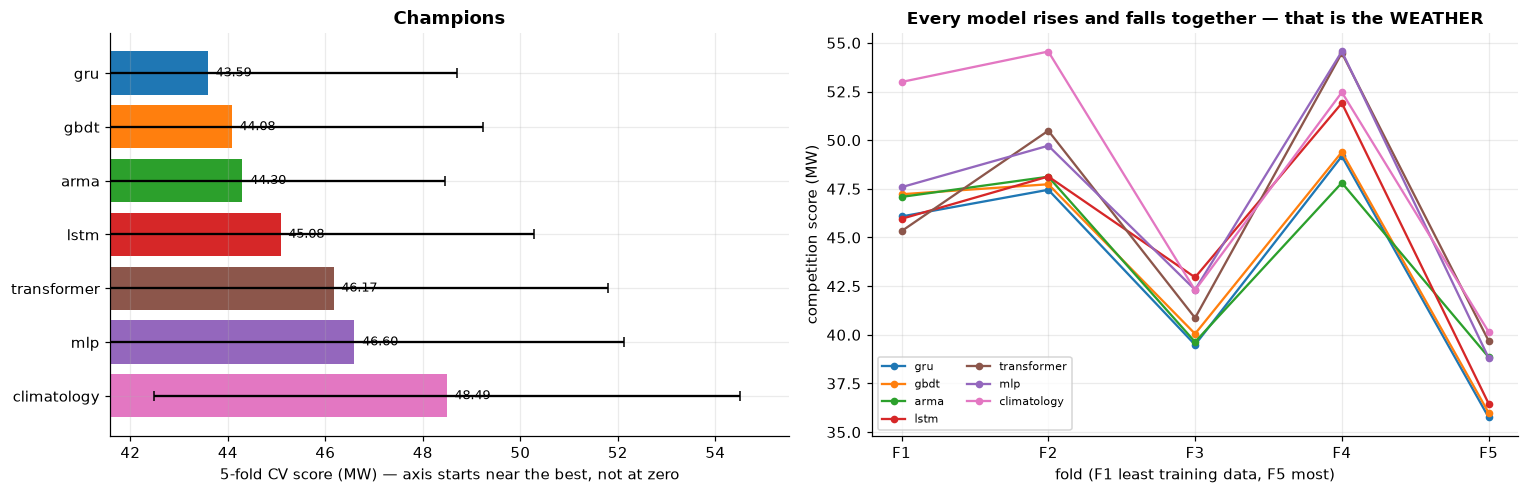

If every model peaks on the same fold, that fold is genuinely harder --
a property of the DATA. If only one model does, that is the model.


In [8]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.6),
                        gridspec_kw={"width_ratios": [1.05, 1]})

c = cv.sort_values("cv_mean")
y = np.arange(len(c))
axs[0].barh(y, c["cv_mean"], xerr=c["fold_std"], capsize=3,
            color=[COLOURS.get(m, "grey") for m in c["model"]])
axs[0].set_yticks(y); axs[0].set_yticklabels(c["model"]); axs[0].invert_yaxis()
axs[0].set_xlim(c["cv_mean"].min() - 2, c["cv_mean"].max() + c["fold_std"].max() + 1)
for i, (_, r) in enumerate(c.iterrows()):
    axs[0].annotate("{:.2f}".format(r["cv_mean"]), (r["cv_mean"], i),
                    xytext=(5, 0), textcoords="offset points", va="center", fontsize=8.5)
axs[0].set_xlabel("5-fold CV score (MW) — axis starts near the best, not at zero")
axs[0].set_title("Champions", fontweight="bold")

x = np.arange(len(FOLDS))
for _, r in c.iterrows():
    axs[1].plot(x, [r[f] for f in FOLDS], "o-", lw=1.5, ms=4,
                color=COLOURS.get(r["model"]), label=r["model"])
axs[1].set_xticks(x); axs[1].set_xticklabels(FOLDS)
axs[1].set_xlabel("fold (F1 least training data, F5 most)")
axs[1].set_ylabel("competition score (MW)")
axs[1].set_title("Every model rises and falls together — that is the WEATHER",
                 fontweight="bold", fontsize=11)
axs[1].legend(fontsize=7.5, ncol=2)

plt.tight_layout(); plt.show()

print("If every model peaks on the same fold, that fold is genuinely harder --")
print("a property of the DATA. If only one model does, that is the model.")

## 5 · Competition score on `final_phase_test`

The official grader, run through `competition_score.py`, using each model's
**full-245-day** artifact.

This is the externally comparable number: published GRU baseline **47.850 MW**,
best KDD Cup entry (HIK) **44.917 MW**.

> **Score each configuration once.** Repeatedly scoring on the test set turns it
> into another validation split. The configurations here were chosen on the folds
> and are frozen.

In [9]:
if not RUN_TEST:
    print("RUN_TEST is False -- skipped")
elif not os.path.isdir(P.TEST_DIR):
    print("no test directory at {} -- skipped".format(P.TEST_DIR))
else:
    import competition_score as CS

    n_in = len(glob.glob(os.path.join(P.TEST_DIR, "infile", "*in.csv")))
    print("test windows: {}\n".format(n_in))

    test_rows = []
    for name in TEST_MODELS:
        spec = MODELS[name]
        # Point the program at its FULL-DATA artifact. competition_score loads
        # the program from its path, so the env var must be set beforehand -- and
        # it must NOT contain "{fold}", since the test set has no folds.
        if spec["env"]:
            os.environ[spec["env"]] = art_path(name, "full")
        prog = os.path.join(_ROOT, "baselines", spec["path"])
        t0 = time.perf_counter()
        try:
            res = CS.score(prog, P.TEST_DIR)
            test_rows.append(dict(
                model=name, champion=spec["champion"],
                test_score=round(res["competition_score"], 3),
                total_mae=round(res["total_mae"], 3),
                total_rmse=round(res["total_rmse"], 3),
                accuracy=round(res["accuracy"] * 100, 2),
                windows=res["n_windows"],
                secs=round(time.perf_counter() - t0, 1)))
            print("{:<13} {:8.3f} MW   acc {:.1f}%   ({:.0f}s)".format(
                name, res["competition_score"], res["accuracy"] * 100,
                test_rows[-1]["secs"]))
        except Exception as e:
            print("{:<13} FAILED: {}: {}".format(name, type(e).__name__, str(e)[:70]))

    test = pd.DataFrame(test_rows).sort_values("test_score").reset_index(drop=True)
    print()
    display(test)

    if (test["test_score"] == 65535).any():
        print("\n65535 is the OFFICIAL SENTINEL for an incomplete run -- not a score.")
        print("It means fewer windows were graded than the grader requires.")

test windows: 142


	The 0-th prediction -- RMSE: 50.69806019856495, MAE: 38.43603166209439, Score: 44.56704593032967, and Accuracy: 54.6972%

	The 1-th prediction -- RMSE: 50.27433507569283, MAE: 35.98181834392778, Score: 43.1280767098103, and Accuracy: 63.3483%

	The 2-th prediction -- RMSE: 64.84642899811179, MAE: 50.90913691567192, Score: 57.877782956891856, and Accuracy: 58.5642%

	The 3-th prediction -- RMSE: 46.98207567109468, MAE: 35.754056525940584, Score: 41.36806609851763, and Accuracy: 67.0087%

	The 4-th prediction -- RMSE: 40.50683019925259, MAE: 30.633208392692023, Score: 35.57001929597231, and Accuracy: 76.5412%

	The 5-th prediction -- RMSE: 40.40595009882716, MAE: 32.22273412443847, Score: 36.31434211163281, and Accuracy: 66.9806%

	The 6-th prediction -- RMSE: 65.08306571482811, MAE: 51.791217536349365, Score: 58.43714162558874, and Accuracy: 46.1440%

	The 7-th prediction -- RMSE: 63.38440119077994, MAE: 51.14334771826567, Score: 57.263874454522806, and Accuracy: 46

,model,champion,test_score,total_mae,total_rmse,accuracy,windows,secs
0,gbdt,tier = base+nbr,46.785,42.032,51.537,60.28,142,34.9
1,gru,hidden = 96,46.859,42.140,51.578,60.31,142,38.3
2,transformer,patch_len = 24,48.617,43.799,53.434,58.96,142,35.7
3,climatology,n_days = 14,49.127,44.483,53.772,59.80,142,32.8
4,arma,"order = (2,0,1)",49.385,43.745,55.024,57.65,142,100.2


In [12]:
import numpy as np, glob
from test_data import TestData

ins = sorted(glob.glob(os.path.join(P.TEST_DIR, "infile", "*in.csv")))
outs = sorted(glob.glob(os.path.join(P.TEST_DIR, "outfile", "*out.csv")))
W = 119                                    # 0-based index of the 120th

for name in ["gru", "lstm", "mlp"]:
    spec = MODELS[name]
    os.environ[spec["env"]] = art_path(name, "full")
    mod = load_model(name, "full")
    envs = EV._prep_env(ins[W], P.TRAIN_FILE, None)
    envs["path_to_locations"] = P.LOCATION_FILE
    p = np.asarray(mod.forecast(envs)).reshape(EV.CAPACITY, EV.OUTPUT_LEN)

    td = TestData(path_to_data=outs[W], start_col=EV.START_COL, farm_capacity=EV.CAPACITY)
    tb, _ = td.get_all_turbines()
    truth = np.array([np.asarray(tb[i])[:EV.OUTPUT_LEN, -EV.OUT_VAR:].ravel()
                      for i in range(EV.CAPACITY)])

    print("%-6s pred [%7.1f, %7.1f] mean %6.1f | truth [%6.1f, %6.1f] mean %6.1f | MAE %6.1f kW"
          % (name, p.min(), p.max(), p.mean(),
             truth.min(), truth.max(), truth.mean(),
             np.abs(p - truth).mean()))

gru    pred [   72.8,   974.0] mean  396.3 | truth [  -6.6, 1560.7] mean  290.5 | MAE  348.9 kW
lstm   pred [   63.6,   999.3] mean  322.3 | truth [  -6.6, 1560.7] mean  290.5 | MAE  331.7 kW
mlp    pred [    0.0,  1059.3] mean  367.1 | truth [  -6.6, 1560.7] mean  290.5 | MAE  351.7 kW


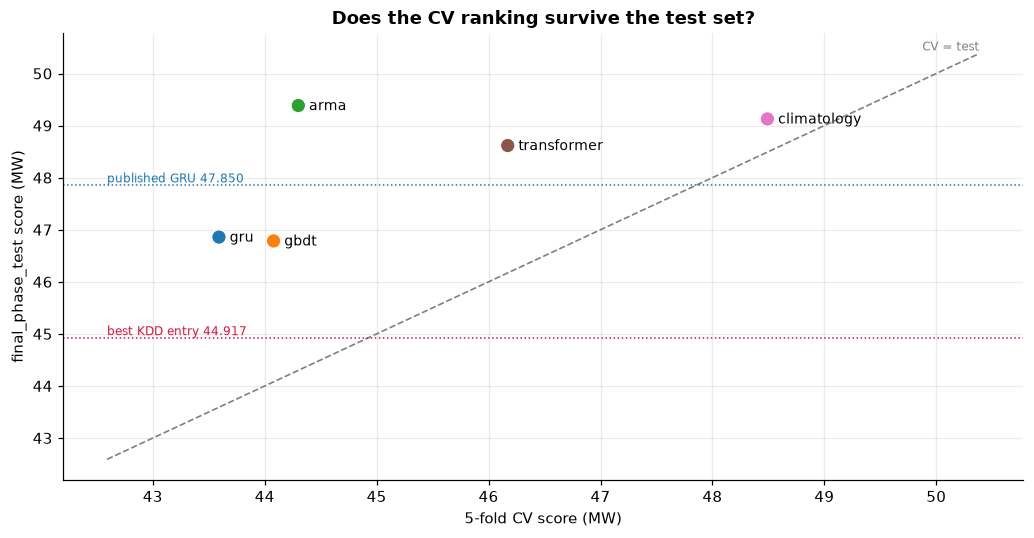

Spearman rank correlation, CV vs test: +0.600

Weak agreement. The CV ranking is only loosely predictive here.


,model,champion,cv_mean,fold_std,test_score,cv_minus_test
1,gbdt,tier = base+nbr,44.079,5.159,46.785,-2.706
0,gru,hidden = 96,43.591,5.109,46.859,-3.268
3,transformer,patch_len = 24,46.171,5.630,48.617,-2.446
4,climatology,n_days = 14,48.491,6.012,49.127,-0.636
2,arma,"order = (2,0,1)",44.300,4.152,49.385,-5.085


In [10]:
if RUN_TEST and "test" in dir() and len(test):
    both = cv.merge(test[["model", "test_score"]], on="model", how="inner")
    both["cv_minus_test"] = (both["cv_mean"] - both["test_score"]).round(3)
    both = both.sort_values("test_score")

    fig, ax = plt.subplots(figsize=(9.5, 5))
    ax.scatter(both["cv_mean"], both["test_score"], s=90,
               color=[COLOURS.get(m, "grey") for m in both["model"]],
               edgecolor="white", linewidth=0.8, zorder=5)
    for _, r in both.iterrows():
        ax.annotate(r["model"], (r["cv_mean"], r["test_score"]),
                    xytext=(7, -3), textcoords="offset points", fontsize=9)
    lo = min(both["cv_mean"].min(), both["test_score"].min()) - 1
    hi = max(both["cv_mean"].max(), both["test_score"].max()) + 1
    ax.plot([lo, hi], [lo, hi], color="grey", ls="--", lw=1.1)
    ax.annotate("CV = test", (hi, hi), fontsize=8, color="grey",
                ha="right", va="bottom")
    ax.axhline(47.850, color="tab:blue", ls=":", lw=1)
    ax.annotate("published GRU 47.850", (lo, 47.850), fontsize=8, color="tab:blue", va="bottom")
    ax.axhline(44.917, color="crimson", ls=":", lw=1)
    ax.annotate("best KDD entry 44.917", (lo, 44.917), fontsize=8,
                color="crimson", va="bottom")
    ax.set_xlabel("5-fold CV score (MW)"); ax.set_ylabel("final_phase_test score (MW)")
    ax.set_title("Does the CV ranking survive the test set?", fontweight="bold")
    plt.tight_layout(); plt.show()

    r = both[["cv_mean", "test_score"]].corr(method="spearman").iloc[0, 1]
    print("Spearman rank correlation, CV vs test: {:+.3f}".format(r))
    print()
    if r > 0.7:
        print("The CV ranking largely holds. Selecting on folds picked sensibly.")
    elif r > 0:
        print("Weak agreement. The CV ranking is only loosely predictive here.")
    else:
        print("NEGATIVE -- the CV ranking inverted on the test set. That is the same")
        print("failure the old single split showed (rho about -0.20), and it would")
        print("mean fold selection is not transferring.")
    display(both[["model", "champion", "cv_mean", "fold_std", "test_score", "cv_minus_test"]])

## 6 · Summary

Everything in one table. **Nothing is written to disk** — the figures and tables
above live in this notebook, and re-running it reproduces them from the saved
models.

In [11]:
summary = cv[["model", "champion"] + FOLDS + ["cv_mean", "fold_std"]].copy()

if RUN_TEST and "test" in dir() and len(test):
    summary = summary.merge(test[["model", "test_score"]], on="model", how="left")
    summary["cv_minus_test"] = (summary["cv_mean"] - summary["test_score"]).round(3)

summary = summary.sort_values("cv_mean").reset_index(drop=True)
summary.index += 1
summary.index.name = "rank"

print("BASELINE SUITE")
print("  CV   : 5-fold rolling origin, each fold trained on its own fold_train.csv")
print("  test : final_phase_test, scored with the full 245-day model")
print("  lower is better; the published GRU baseline is 47.850 on the test set\n")
display(summary)

print("\nModels are saved in each baseline's own folder:")
for name, spec in MODELS.items():
    if spec["ext"] is None:
        print("  {:<13} no artifact -- fits nothing".format(name))
        continue
    d = os.path.dirname(art_path(name, "full"))
    n = len([t for t in FOLDS + ["full"] if os.path.exists(art_path(name, t))])
    print("  {:<13} {}/  ({} files)".format(name, os.path.relpath(d, _ROOT), n))

BASELINE SUITE
  CV   : 5-fold rolling origin, each fold trained on its own fold_train.csv
  test : final_phase_test, scored with the full 245-day model
  lower is better; the published GRU baseline is 47.850 on the test set



,model,champion,F1,F2,F3,F4,F5,cv_mean,fold_std,test_score,cv_minus_test
rank,,,,,,,,,,,
1,gru,hidden = 96,46.080,47.452,39.488,49.178,35.759,43.591,5.109,46.859,-3.268
2,gbdt,tier = base+nbr,47.222,47.735,40.051,49.393,35.994,44.079,5.159,46.785,-2.706
3,arma,"order = (2,0,1)",47.085,48.122,39.633,47.811,38.850,44.300,4.152,49.385,-5.085
4,lstm,GRU-matched,45.959,48.134,42.951,51.905,36.464,45.083,5.205,NaN,NaN
5,transformer,patch_len = 24,45.326,50.488,40.868,54.480,39.691,46.171,5.630,48.617,-2.446
6,mlp,scope = global,47.585,49.716,42.314,54.559,38.814,46.598,5.532,NaN,NaN
7,climatology,n_days = 14,52.992,54.556,42.294,52.462,40.152,48.491,6.012,49.127,-0.636



Models are saved in each baseline's own folder:
  gru           baselines/gru/checkpoints/  (6 files)
  gbdt          baselines/tree/checkpoints/  (6 files)
  arma          baselines/classical/checkpoints/  (6 files)
  lstm          baselines/lstm/checkpoints/  (6 files)
  mlp           baselines/mlp/checkpoints/  (6 files)
  transformer   baselines/transformer/checkpoints/  (6 files)
  climatology   no artifact -- fits nothing


### Using a saved model from the command line

The artifacts sit where each baseline already looks, so they work directly:

```bash
cd windevolve_sdwpf

# one fold
SDWPF_GRU_CKPT=baselines/gru/checkpoints/gru_F3.pt \
  python evaluation/evaluator.py baselines/gru/gru_baseline.py \
      --val-dir evaluation/splits_rolling_5x30/F3/windows \
      --train-file evaluation/splits_rolling_5x30/F3/fold_train.csv

# the full-data model on the test set
SDWPF_GRU_CKPT=baselines/gru/checkpoints/gru_full.pt \
  python evaluation/competition_score.py baselines/gru/gru_baseline.py
```

The `_full` artifact is the one to keep — it is trained on all 245 days and is
what any test-set scoring should use. The per-fold artifacts only matter for
reproducing the CV numbers.